In [2]:
import os, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt

DATA_DIR = "/kaggle/input/competitions/brain-to-text-25"
SESSIONS_DIR = f"{DATA_DIR}/t15_copyTask_neuralData/hdf5_data_final"

# Phoneme ID → name, copied from the official repo (evaluate_model_helpers.py)
LOGIT_TO_PHONEME = ['BLANK','AA','AE','AH','AO','AW','AY','B','CH','D','DH','EH','ER','EY','F','G',
                    'HH','IH','IY','JH','K','L','M','N','NG','OW','OY','P','R','S','SH','T','TH',
                    'UH','UW','V','W','Y','Z','ZH',' | ']

In [5]:
f = h5py.File(f"{SESSIONS_DIR}/t15.2023.08.13/data_train.hdf5", "r")
keys = list(f.keys())
print(len(keys), "trials. First few:", keys[:3])

g = f[keys[0]]
print("Datasets:", list(g.keys()))
print("Attributes:", dict(g.attrs))

348 trials. First few: ['trial_0000', 'trial_0001', 'trial_0002']
Datasets: ['input_features', 'seq_class_ids', 'transcription']
Attributes: {'block_num': np.int64(1), 'n_time_steps': np.int64(1023), 'sentence_label': 'Which is most unfortunate because we all lose out.', 'seq_len': np.int64(42), 'session': 't15.2023.08.13', 'trial_num': np.int64(0)}


In [6]:
x = g["input_features"][:]
print("Neural data shape:", x.shape, "→ (time bins, features)")
print("Duration:", x.shape[0] * 0.02, "seconds")
print("Sentence:", g.attrs["sentence_label"])

ids = g["seq_class_ids"][:g.attrs["seq_len"]]   # cut off the padding
print("Phonemes:", " ".join(LOGIT_TO_PHONEME[i] for i in ids))

Neural data shape: (1023, 512) → (time bins, features)
Duration: 20.46 seconds
Sentence: Which is most unfortunate because we all lose out.
Phonemes: W IH CH  |  IH Z  |  M OW S T  |  AH N F AO R CH AH N AH T  |  B IH K AO Z  |  W IY  |  AO L  |  L UW Z  |  AW T  | 


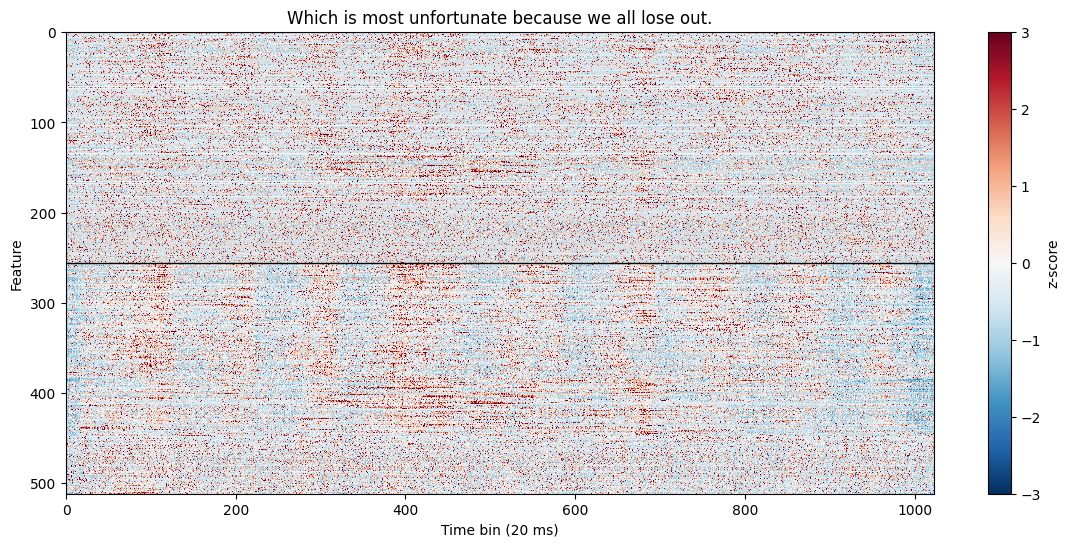

Threshold crossings mean: -0.000120724166  std: 0.99855936
Spike band power mean:   -4.629096e-05  std: 0.9994881


In [10]:
z = (x - x.mean(0)) / (x.std(0) + 1e-6)   # z-score each feature so they're comparable
plt.figure(figsize=(14, 6))
plt.imshow(z.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
plt.axhline(255.5, color="k", lw=1)        # top half: threshold crossings / bottom: spike band power
plt.xlabel("Time bin (20 ms)"); plt.ylabel("Feature"); plt.colorbar(label="z-score")
plt.title(g.attrs["sentence_label"]); plt.show()
print("Threshold crossings mean:", x[:, :256].mean(), " std:", x[:, :256].std())
print("Spike band power mean:  ", x[:, 256:].mean(), " std:", x[:, 256:].std())

**Why the heatmap needed z-scoring:** the released features were already normalized (mean ≈ 0, std ≈ 1 for both threshold crossing and spike band power), so per-trial z-scoring barely changed the heatmap whatsoever. Models must use the same input preprocessing for a fair comparision.

split
test     1450
train    8072
val      1426
Name: n_trials, dtype: int64 
Total: 10948


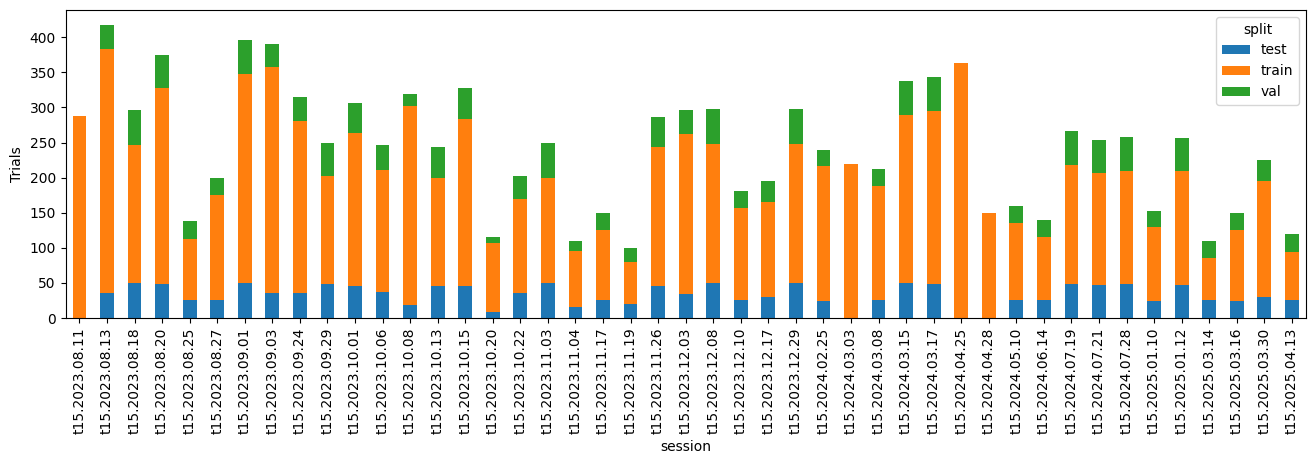

In [8]:
rows = []
for s in sorted(os.listdir(SESSIONS_DIR)):
    for split in ["train", "val", "test"]:
        p = f"{SESSIONS_DIR}/{s}/data_{split}.hdf5"
        if os.path.exists(p):
            with h5py.File(p, "r") as h:
                rows.append((s, split, len(h.keys())))
df = pd.DataFrame(rows, columns=["session", "split", "n_trials"])

print(df.groupby("split").n_trials.sum(), "\nTotal:", df.n_trials.sum())
df.pivot(index="session", columns="split", values="n_trials").plot(kind="bar", stacked=True, figsize=(16, 4))
plt.ylabel("Trials"); plt.show()

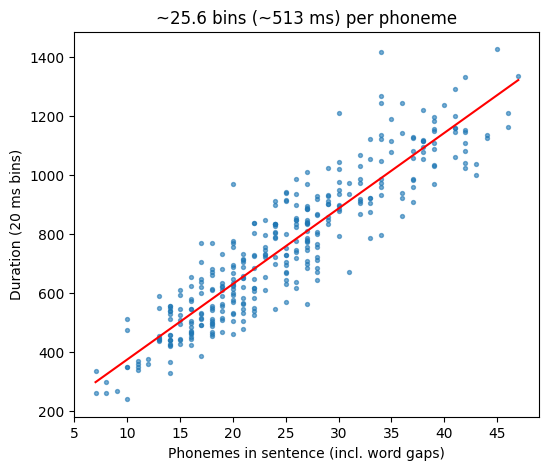

In [11]:
f = h5py.File(f"{SESSIONS_DIR}/t15.2023.08.13/data_train.hdf5", "r")
n_bins = np.array([f[k].attrs["n_time_steps"] for k in f.keys()])
n_phon = np.array([f[k].attrs["seq_len"] for k in f.keys()])

m, b = np.polyfit(n_phon, n_bins, 1)          # best-fit line
plt.figure(figsize=(6, 5))
plt.scatter(n_phon, n_bins, s=8, alpha=0.6)
plt.plot([n_phon.min(), n_phon.max()], [m*n_phon.min()+b, m*n_phon.max()+b], "r")
plt.xlabel("Phonemes in sentence (incl. word gaps)"); plt.ylabel("Duration (20 ms bins)")
plt.title(f"~{m:.1f} bins (~{m*20:.0f} ms) per phoneme"); plt.show()

**Duration vs. phoneme count:** the points form a rough straight linear graph. This makes sense since longer sentences take proportionally longer temporal space. The slope tells you she speaks at roughly a few hundred ms per phoneme, much slower than normal speech because she is attempting to speak with paralysis. Points far above the line are trials with some pauses or hesitation.

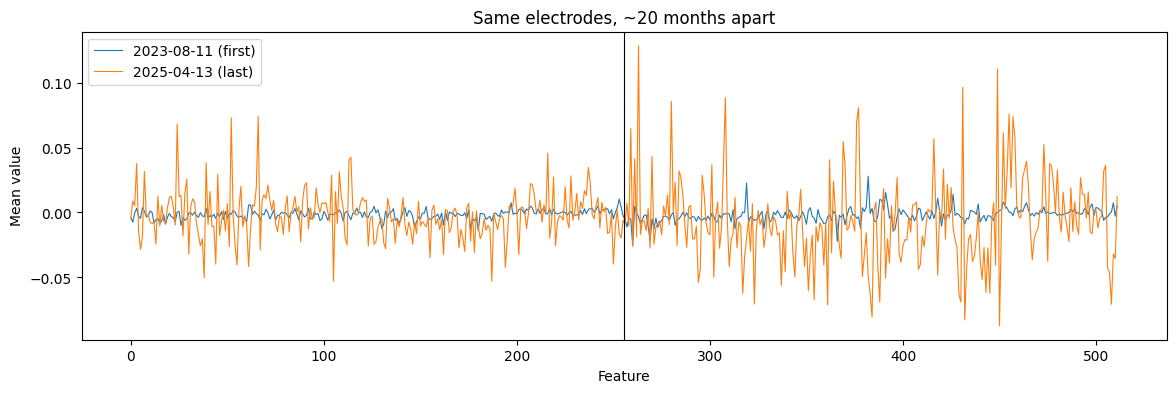

Features that drifted most: [263 449 431 308 450 280 377 384 388 382]


In [12]:
def session_mean(session):
    with h5py.File(f"{SESSIONS_DIR}/{session}/data_train.hdf5", "r") as h:
        X = np.concatenate([h[k]["input_features"][:] for k in h.keys()], axis=0)
    return X.mean(axis=0)

first = session_mean("t15.2023.08.11")
last  = session_mean("t15.2025.04.13")

plt.figure(figsize=(14, 4))
plt.plot(first, lw=0.8, label="2023-08-11 (first)")
plt.plot(last,  lw=0.8, label="2025-04-13 (last)")
plt.axvline(255.5, color="k", lw=0.8)
plt.xlabel("Feature"); plt.ylabel("Mean value"); plt.legend()
plt.title("Same electrodes, ~20 months apart"); plt.show()

top = np.argsort(np.abs(last - first))[::-1][:10]
print("Features that drifted most:", top)

The two lines don't overlap. The same electrode reports a different baseline 20 months later, because tissue grows around the arrays, the arrays shift slightly, and the neurons near each electrode change. This is the phenomena known as **neural drift.**

ventral 6v   modulation (std): 0.176
area 4       modulation (std): 0.157
55b          modulation (std): 0.176
dorsal 6v    modulation (std): 0.136


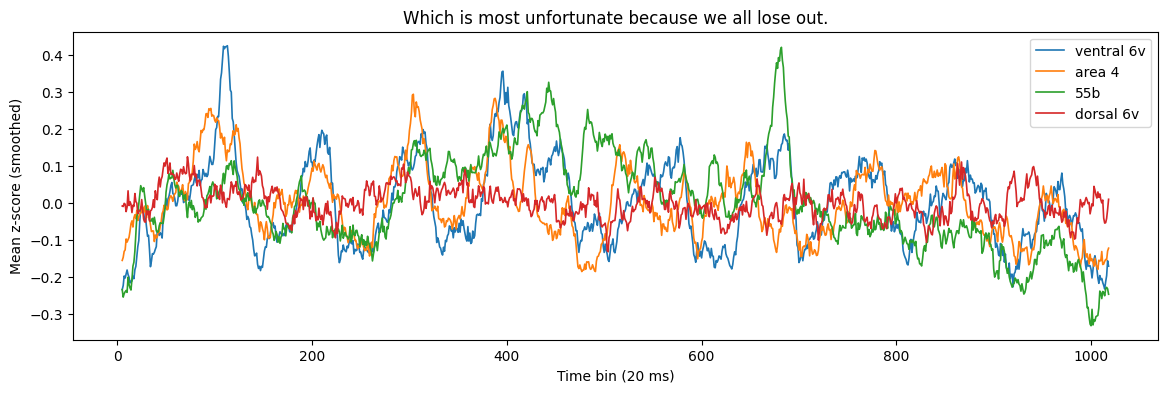

In [13]:
areas = {"ventral 6v": (0, 64), "area 4": (64, 128), "55b": (128, 192), "dorsal 6v": (192, 256)}

plt.figure(figsize=(14, 4))
for name, (a, b) in areas.items():
    trace = pd.Series(z[:, a:b].mean(axis=1)).rolling(10, center=True).mean()  # smooth over 200 ms
    plt.plot(trace, lw=1.2, label=name)
    print(f"{name:12s} modulation (std): {z[:, a:b].mean(axis=1).std():.3f}")
plt.xlabel("Time bin (20 ms)"); plt.ylabel("Mean z-score (smoothed)"); plt.legend()
plt.title(g.attrs["sentence_label"]); plt.show()

**Brain-area activity:** each line is one 64-electrode Utah array average together. The array whose line rises and falls the most (largest printed std) is most strongly tied to speaking in this trial, and its peaks should like up with the vertical stripes in my heatmap, which are moments of attempted speech. One trials is a small sample, so this is just a first glimpse, not final results.

In [14]:
counts = df.pivot(index="session", columns="split", values="n_trials").fillna(0)
print(counts[(counts["val"] == 0) | (counts["test"] == 0)])

split           test  train  val
session                         
t15.2023.08.11   0.0  288.0  0.0
t15.2024.03.03   0.0  219.0  0.0
t15.2024.04.25   0.0  364.0  0.0
t15.2024.04.28   0.0  150.0  0.0
